Figure 1b

In [ ]:
# Dependencies: numpy, pandas, matplotlib.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

COMPARISON_DIR = Path("data/gravity_comparison")
YEARS = np.arange(2017, 2023)
GRAVITY_SOURCE = 'GPS'
SOURCE_ORDER = ('observed', GRAVITY_SOURCE)
OUTCOMES = ('existence', 'birth', 'dissolution')
PANEL_SPECS = (
    ('Existence', 'existence', '#b89d47'),
    ('Formation', 'birth', '#72b0ab'),
    ('Dissolution', 'dissolution', '#fe9179'),
)
GRAVITY_COLOR = '#808080'
ZERO_COLOR = '#053229'
GRID_COLOR = '#bcdddc'


In [2]:
coefficients = pd.read_csv(COMPARISON_DIR / 'standardized_log_mp_coefficients.csv')
coefficients = coefficients.loc[coefficients['mp_source'].isin(SOURCE_ORDER)].copy()
statistics = pd.read_csv(COMPARISON_DIR / 'model_statistics.csv')
statistics = statistics.loc[statistics['mp_source'].isin(SOURCE_ORDER)].copy()
scaling = pd.read_csv(COMPARISON_DIR / 'standardization_parameters.csv')
scaling = scaling.loc[scaling['mp_source'].isin(SOURCE_ORDER)].copy()

keys = ['outcome', 'year', 'mp_source']
coefficients = coefficients.merge(scaling[keys + ['log_mp_sd']], on=keys, how='left')
coefficient_columns = ['estimate', 'std_error', 'conf_low', 'conf_high']
coefficients[coefficient_columns] = coefficients[coefficient_columns].div(
    coefficients['log_mp_sd'], axis=0
)
coefficients['term'] = 'log_MP'

aic_pairs = statistics.pivot(index=['outcome', 'year'], columns='mp_source', values='aic')
delta_aic = aic_pairs.rename(columns={
    'observed': 'aic_observed', GRAVITY_SOURCE: 'aic_gravity'
}).reset_index()
delta_aic['delta_aic'] = delta_aic['aic_observed'] - delta_aic['aic_gravity']


In [3]:
panels = []
for title, outcome, color in PANEL_SPECS:
    by_source = {}
    for source in SOURCE_ORDER:
        data = coefficients.loc[
            coefficients['outcome'].eq(outcome)
            & coefficients['mp_source'].eq(source)
        ].sort_values('year').copy()
        by_source[source] = data
    fit = delta_aic.loc[delta_aic['outcome'].eq(outcome)].sort_values('year').copy()
    panels.append((title, by_source, fit, color))

y_low = min(0.0, coefficients['conf_low'].min())
y_high = max(0.0, coefficients['conf_high'].max())
coefficient_padding = max((y_high - y_low) * 0.08, 1e-3)

def format_delta(value):
    return f'{value:.1f}' if abs(value) >= 10 else f'{value:.2f}'


In [4]:
def draw_comparison_figure(STYLE):
    with mpl.rc_context():
        mpl.rcParams.update({
            'font.family': STYLE['font_family'],
            'font.size': STYLE['font_size'],
            'axes.labelsize': STYLE['label_size'],
            'axes.titlesize': STYLE['title_size'],
            'axes.titleweight': STYLE['title_weight'],
            'axes.labelpad': STYLE['label_pad'],
            'xtick.labelsize': STYLE['tick_size'],
            'ytick.labelsize': STYLE['tick_size'],
            'xtick.major.pad': STYLE['tick_pad'],
            'ytick.major.pad': STYLE['tick_pad'],
            'axes.linewidth': 0.7,
            'axes.spines.top': False,
            'axes.spines.right': False,
            'pdf.fonttype': 42,
            'ps.fonttype': 42,
            'savefig.facecolor': 'white',
            'figure.facecolor': 'white',
            'figure.constrained_layout.w_pad': STYLE['w_pad'],
            'figure.constrained_layout.h_pad': STYLE['h_pad'],
        })

        fig = plt.figure(figsize=STYLE['figsize'], dpi=100, layout='constrained')

        outer_grid = fig.add_gridspec(
            2, 1, height_ratios=(STYLE['legend_height'], 1), hspace=0)
        legend_ax = fig.add_subplot(outer_grid[0, 0])
        legend_ax.set_axis_off()
        grid = outer_grid[1, 0].subgridspec(
            2, 3, height_ratios=STYLE['height_ratios'],
            hspace=STYLE['hspace'], wspace=STYLE['wspace'])
        coefficient_axes = []
        aic_axes = []

        for column, panel in enumerate(panels):
            title, by_source, fit, color = panel
            shared_y = coefficient_axes[0] if coefficient_axes else None
            ax = fig.add_subplot(grid[0, column], sharey=shared_y)
            ax_aic = fig.add_subplot(grid[1, column], sharex=ax)
            coefficient_axes.append(ax)
            aic_axes.append(ax_aic)

            ax.axhline(0, color=ZERO_COLOR, linewidth=0.7, linestyle='--', zorder=1)
            for source, line_color, marker, linestyle, offset, label in [
                ('observed', color, 'o', '-', 0.0, 'Observed MP'),
                (GRAVITY_SOURCE, GRAVITY_COLOR, 's', '--', 0.12, 'Gravity MP'),
            ]:
                data = by_source[source]
                lower = data['estimate'].to_numpy() - data['conf_low'].to_numpy()
                upper = data['conf_high'].to_numpy() - data['estimate'].to_numpy()
                ax.errorbar(data['year'].to_numpy() + offset, data['estimate'],
                            yerr=[lower, upper], marker=marker, linestyle=linestyle,
                            color=line_color, linewidth=STYLE['line_width'], markersize=STYLE['marker_size'],
                            markeredgecolor='white', markeredgewidth=0.6,
                            elinewidth=STYLE['errorbar_width'], capsize=STYLE['capsize'], zorder=3, label=label)
            ax.set_title(title, pad=STYLE['title_pad'])
            ax.set_ylim(y_low - coefficient_padding, y_high + coefficient_padding)
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.grid(axis='y', color=GRID_COLOR, linewidth=0.45, alpha=0.55)
            ax.tick_params(labelbottom=False, bottom=False, labelleft=(column == 0))

            values = fit['delta_aic'].to_numpy(dtype=float)
            colors = [GRAVITY_COLOR if value >= 0 else color for value in values]
            ax_aic.axhline(0, color=ZERO_COLOR, linewidth=0.7, zorder=1)
            ax_aic.vlines(YEARS, 0, values, colors=colors, linewidth=1.0, alpha=0.85, zorder=2)
            ax_aic.scatter(YEARS, values, c=colors, s=18,
                           edgecolors='white', linewidths=0.5, zorder=3)
            aic_low = min(0.0, float(values.min()))
            aic_high = max(0.0, float(values.max()))
            aic_padding = max((aic_high - aic_low) * 0.30, 0.5)
            ax_aic.set_ylim(aic_low - aic_padding, aic_high + aic_padding)
            ax_aic.yaxis.set_major_locator(MaxNLocator(nbins=3))
            ax_aic.grid(axis='y', color=GRID_COLOR, linewidth=0.4, alpha=0.45)
            ax_aic.set_xlabel(STYLE['x_label'])
            ax_aic.set_xticks(YEARS)
            plt.setp(ax_aic.get_xticklabels(),
                     rotation=STYLE['year_rotation'],
                     ha=STYLE['year_alignment'], rotation_mode='anchor')

            for axis in (ax, ax_aic):
                axis.set_xlim(2016.6, 2022.4)
                axis.tick_params(direction='out', length=3, width=0.7)
                for spine in axis.spines.values():
                    spine.set_visible(False)

        from matplotlib.lines import Line2D
        from matplotlib.legend_handler import HandlerTuple

        observed_handles = tuple(
            Line2D([], [], color=color, marker='o', linestyle='-',
                   linewidth=STYLE['line_width'], markersize=STYLE['marker_size'],
                   markeredgecolor='white', markeredgewidth=0.6)
            for _, _, color in PANEL_SPECS
        )
        gravity_handle = Line2D(
            [], [], color=GRAVITY_COLOR, marker='s', linestyle='--',
            linewidth=STYLE['line_width'], markersize=STYLE['marker_size'],
            markeredgecolor='white', markeredgewidth=0.6)
        legend_ax.legend(
            [observed_handles, gravity_handle], ['Observed MP', 'Gravity MP'],
            handler_map={tuple: HandlerTuple(ndivide=None, pad=0.4)},
            frameon=False, fontsize=STYLE['legend_size'], loc=STYLE['legend_loc'],
            ncol=STYLE['legend_ncol'], handlelength=4, columnspacing=2)

        coefficient_axes[0].set_ylabel(STYLE['coefficient_label'])
        aic_axes[0].set_ylabel(STYLE['aic_label'])
        fig.supxlabel(STYLE['caption'], fontsize=STYLE['caption_size'])
        return fig, coefficient_axes, aic_axes


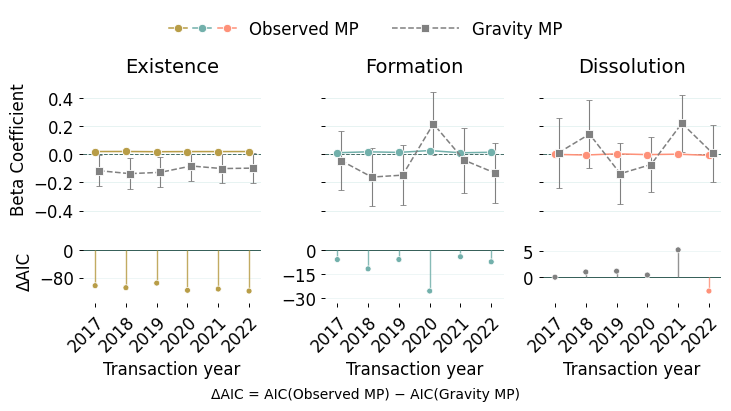

In [ ]:
STYLE = {
    'font_family': 'DejaVu Sans',
    'font_size': 12,
    'title_size': 14,
    'title_weight': 'normal',
    'label_size': 12,
    'tick_size': 12,
    'year_rotation': 45,
    'year_alignment': 'right',
    'legend_size': 12,
    'caption_size': 10,
    'figsize': (7.2, 4),
    'height_ratios': (2, 1.0),
    'hspace': 0.08,
    'wspace': 0.08,
    'w_pad': 0.04167,
    'h_pad': 0.04167,
    'title_pad': 8,
    'label_pad': 4,
    'tick_pad': 3.5,
    'legend_loc': 'center',
    'legend_ncol': 2,
    'legend_height': 0.12,
    'line_width': 1.1,
    'marker_size': 6,
    'errorbar_width': 0.8,
    'capsize': 2,
    'x_label': 'Transaction year',
    'coefficient_label': 'Beta Coefficient',
    'aic_label': 'ΔAIC',
    'caption': 'ΔAIC = AIC(Observed MP) − AIC(Gravity MP)',
}

fig, coefficient_axes, aic_axes = draw_comparison_figure(STYLE)
plt.show()
